<a href="https://colab.research.google.com/github/dimonkOHYRY111/pattern-recognition-practice/blob/classification-mini-project/classification-mini-project/notebooks/PR04_Kochura_Dmytro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практична робота №4
## Підготовка даних, Pipeline і логістична регресія

**Дисципліна:** Розпізнавання образів і машинне навчання

**Студент:** Кочура Д.С.

**Група:** ІН-32.

**Дата виконання:** 08.11.2026

### Мета роботи

Навчитися готувати дані, створювати Pipeline, досліджувати логістичну регресію та оцінювати моделі за допомогою крос-валідації.

In [1]:

!pip -q install ucimlrepo

from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from google.colab import drive
from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    cross_validate, GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression


In [2]:

drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/patternrecognition-practice"
)

MINI_DIR = PROJECT_DIR / "classification-mini-project"
DATA_DIR = MINI_DIR / "data"
NOTEBOOKS_DIR = MINI_DIR / "notebooks"
MODELS_DIR = MINI_DIR / "models"
REPORTS_DIR = MINI_DIR / "reports"

for folder in [DATA_DIR, NOTEBOOKS_DIR, MODELS_DIR, REPORTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_PATH = DATA_DIR / "heart_disease.csv"

print("Папка проєкту:", MINI_DIR)
print("Папка даних:", DATA_DIR)


Mounted at /content/drive
Папка проєкту: /content/drive/MyDrive/patternrecognition-practice/classification-mini-project
Папка даних: /content/drive/MyDrive/patternrecognition-practice/classification-mini-project/data


In [3]:

if DATA_PATH.exists():
    data = pd.read_csv(DATA_PATH)
    print("Дані завантажено з CSV.")
else:
    heart = fetch_ucirepo(id=45)

    data = heart.data.features.copy()
    original_target = heart.data.targets["num"]

    # Перетворення на бінарну класифікацію
    data["target"] = (original_target > 0).astype(int)

    data.to_csv(DATA_PATH, index=False)
    print("Файл heart_disease.csv створено.")

display(data.head())
print("Розмір:", data.shape)
print("Файл:", DATA_PATH)


Файл heart_disease.csv створено.


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


Розмір: (303, 14)
Файл: /content/drive/MyDrive/patternrecognition-practice/classification-mini-project/data/heart_disease.csv


## 1. Первинний аналіз даних

На цьому етапі перевіряється структура набору даних, типи ознак, пропущені значення та розподіл класів.

In [4]:

print("Розмір таблиці:", data.shape)

print("\nТипи даних:")
print(data.dtypes)

print("\nПропущені значення:")
print(data.isna().sum())

print("\nРозподіл класів:")
print(data["target"].value_counts().sort_index())

print("\nУнікальні класи:")
print(data["target"].unique())

display(data.head(10))


Розмір таблиці: (303, 14)

Типи даних:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
target        int64
dtype: object

Пропущені значення:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

Розподіл класів:
target
0    164
1    139
Name: count, dtype: int64

Унікальні класи:
[0 1]


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,1
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0
5,56,1,2,120,236,0,0,178,0,0.8,1,0.0,3.0,0
6,62,0,4,140,268,0,2,160,0,3.6,3,2.0,3.0,1
7,57,0,4,120,354,0,0,163,1,0.6,1,0.0,3.0,0
8,63,1,4,130,254,0,2,147,0,1.4,2,1.0,7.0,1
9,53,1,4,140,203,1,2,155,1,3.1,3,0.0,7.0,1


In [5]:

numeric_columns = [
    "age", "trestbps", "chol", "thalach", "oldpeak"
]

categorical_columns = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

print("Числові ознаки:", numeric_columns)
print("Категоріальні ознаки:", categorical_columns)
print("Цільова змінна: target")

assert set(numeric_columns + categorical_columns + ["target"]) == set(data.columns)
assert set(data["target"].dropna().unique()) == {0, 1}


Числові ознаки: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Категоріальні ознаки: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']
Цільова змінна: target


In [6]:

audit = pd.DataFrame({
    "Характеристика": [
        "Кількість об'єктів",
        "Кількість вхідних ознак",
        "Кількість числових ознак",
        "Кількість категоріальних ознак",
        "Кількість пропусків",
        "Кількість класів",
        "Позитивний клас"
    ],
    "Значення": [
        len(data),
        data.shape[1] - 1,
        len(numeric_columns),
        len(categorical_columns),
        data.isna().sum().sum(),
        data["target"].nunique(),
        1
    ]
})

display(audit)


,Характеристика,Значення
0,Кількість об'єктів,303
1,Кількість вхідних ознак,13
2,Кількість числових ознак,5
3,Кількість категоріальних ознак,8
4,Кількість пропусків,6
5,Кількість класів,2
6,Позитивний клас,1


## 2. Розділення даних

Дані поділяються на 80% навчальної та 20% тестової вибірки. Тестова вибірка не використовується для вибору моделі.

In [7]:

X = data.drop(columns=["target"])
y = data["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nЧастки класів train:")
print(y_train.value_counts(normalize=True).round(3))

print("\nЧастки класів test:")
print(y_test.value_counts(normalize=True).round(3))


X_train: (242, 13)
X_test: (61, 13)

Частки класів train:
target
0    0.541
1    0.459
Name: proportion, dtype: float64

Частки класів test:
target
0    0.541
1    0.459
Name: proportion, dtype: float64


In [8]:

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "f1": "f1",
    "roc_auc": "roc_auc"
}


In [9]:

def make_pipeline(scale=True):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler() if scale else "passthrough")
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_columns),
        ("cat", categorical_pipeline, categorical_columns)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000,
            solver="liblinear",
            random_state=42
        ))
    ])


## 3. Вплив масштабування

Порівнюються дві логістичні регресії: зі стандартизацією числових ознак та без неї. Оцінювання виконується за однаковою крос-валідацією.

In [10]:

scale_results = []

for scale in [False, True]:
    model = make_pipeline(scale=scale)

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    model.fit(X_train, y_train)

    scale_results.append({
        "scaling": "StandardScaler" if scale else "Без масштабування",
        "CV_F1": scores["test_f1"].mean(),
        "CV_F1_std": scores["test_f1"].std(),
        "CV_ROC_AUC": scores["test_roc_auc"].mean(),
        "CV_ROC_AUC_std": scores["test_roc_auc"].std(),
        "iterations": model.named_steps["classifier"].n_iter_.max()
    })

scale_df = pd.DataFrame(scale_results)
display(scale_df.round(3))


,scaling,CV_F1,CV_F1_std,CV_ROC_AUC,CV_ROC_AUC_std,iterations
0,Без масштабування,0.825,0.007,0.902,0.015,13
1,StandardScaler,0.825,0.007,0.902,0.014,6


## 4. Підбір гіперпараметрів

Досліджується вплив L1- та L2-регуляризації і параметра C. Найкраща конфігурація обирається за середнім CV F1 без використання тестової вибірки.

In [11]:

model = make_pipeline(scale=True)

param_grid = {
    "preprocessor__num__scaler": [
        StandardScaler(), "passthrough"
    ],
    "classifier__penalty": ["l1", "l2"],
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    scoring=scoring,
    refit="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

grid.fit(X_train, y_train)

print("Найкращі параметри:")
print(grid.best_params_)

print("\nНайкраща CV F1:")
print(round(grid.best_score_, 3))


Найкращі параметри:
{'classifier__C': 10, 'classifier__penalty': 'l2', 'preprocessor__num__scaler': StandardScaler()}

Найкраща CV F1:
0.836


In [12]:

results_df = pd.DataFrame(grid.cv_results_)

comparison = results_df[[
    "param_preprocessor__num__scaler",
    "param_classifier__penalty",
    "param_classifier__C",
    "mean_test_f1",
    "std_test_f1",
    "mean_test_roc_auc",
    "std_test_roc_auc"
]].copy()

comparison.columns = [
    "Scaling", "Penalty", "C",
    "CV_F1", "CV_F1_std",
    "CV_ROC_AUC", "CV_ROC_AUC_std"
]

comparison["Scaling"] = comparison["Scaling"].apply(
    lambda x: "Без масштабування"
    if x == "passthrough" else "StandardScaler"
)

comparison = comparison.sort_values(
    "CV_F1", ascending=False
)

display(comparison.round(3))


,Scaling,Penalty,C,CV_F1,CV_F1_std,CV_ROC_AUC,CV_ROC_AUC_std
19,Без масштабування,l2,100.00,0.836,0.013,0.898,0.012
14,StandardScaler,l2,10.00,0.836,0.013,0.900,0.013
18,StandardScaler,l2,100.00,0.836,0.013,0.898,0.012
16,StandardScaler,l1,100.00,0.836,0.013,0.897,0.012
15,Без масштабування,l2,10.00,0.836,0.013,0.902,0.012
17,Без масштабування,l1,100.00,0.832,0.011,0.897,0.012
13,Без масштабування,l1,10.00,0.832,0.011,0.902,0.011
12,StandardScaler,l1,10.00,0.832,0.011,0.902,0.010
11,Без масштабування,l2,1.00,0.825,0.007,0.902,0.015
10,StandardScaler,l2,1.00,0.825,0.007,0.902,0.014


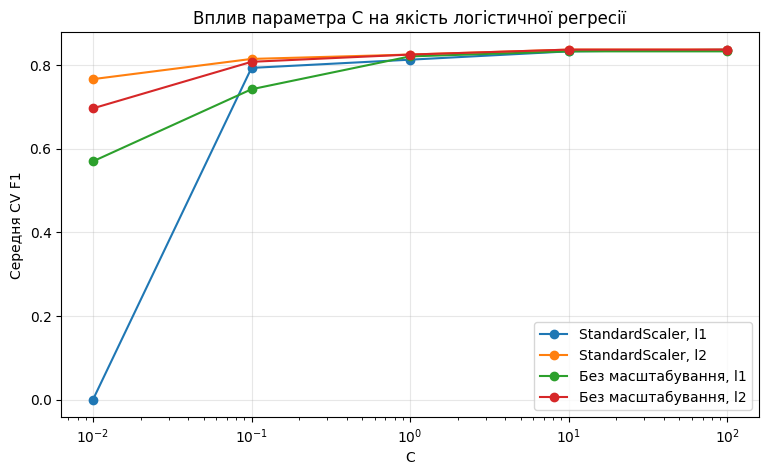

In [13]:

plt.figure(figsize=(9, 5))

for (scaling, penalty), group in comparison.groupby(
    ["Scaling", "Penalty"]
):
    group = group.sort_values("C")

    plt.plot(
        group["C"].astype(float),
        group["CV_F1"],
        marker="o",
        label=f"{scaling}, {penalty}"
    )

plt.xscale("log")
plt.xlabel("C")
plt.ylabel("Середня CV F1")
plt.title("Вплив параметра C на якість логістичної регресії")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


In [14]:

best_model = grid.best_estimator_

feature_names = best_model.named_steps[
    "preprocessor"
].get_feature_names_out()

coefficients = best_model.named_steps[
    "classifier"
].coef_[0]

coef_df = pd.DataFrame({
    "Ознака": feature_names,
    "Коефіцієнт": coefficients,
    "Модуль": abs(coefficients)
})

top_5 = coef_df.sort_values(
    "Модуль", ascending=False
).head(5)

display(top_5.round(3))


,Ознака,Коефіцієнт,Модуль
21,cat__ca_0.0,-1.926,1.926
10,cat__cp_4.0,1.189,1.189
27,cat__thal_7.0,0.978,0.978
7,cat__cp_1.0,-0.892,0.892
5,cat__sex_0.0,-0.880,0.880


## 5. Аналіз коефіцієнтів

Додатні коефіцієнти збільшують прогнозовані log-odds позитивного класу, а від’ємні — зменшують. Більший модуль означає сильніший вплив на лінійний прогноз за інших рівних умов. Це не доводить причинного зв’язку.

## Висновки до практичної роботи №4

Під час роботи підготовлено набір Heart Disease, створено Pipeline та досліджено логістичну регресію.

Проведено порівняння моделей зі стандартизацією та без неї, а також L1- і L2-регуляризації для різних значень C.

Найкращу конфігурацію обрано за результатами крос-валідації на навчальній вибірці. Тестові дані не використовувалися.

# Практична робота №5
## k-NN та ймовірнісні методи класифікації

### Мета роботи

Дослідити метод k найближчих сусідів, Gaussian Naive Bayes, LDA та QDA, порівняти їх за крос-валідацією та визначити найкращі конфігурації.

In [16]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone
import warnings


In [17]:

def make_model_pipeline(classifier, scale=True):

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler() if scale else "passthrough")
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_columns),
        ("cat", categorical_pipeline, categorical_columns)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])


## 1. Дослідження k-NN

Метод k найближчих сусідів визначає клас об’єкта за його найближчими сусідами. Масштабування важливе, оскільки ознаки з великими значеннями можуть сильніше впливати на відстань.

In [18]:

knn_scaling_results = []

for scale in [False, True]:

    model = make_model_pipeline(
        KNeighborsClassifier(n_neighbors=5),
        scale=scale
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    knn_scaling_results.append({
        "Scaling": "StandardScaler" if scale else "Без масштабування",
        "CV_F1": scores["test_f1"].mean(),
        "CV_F1_std": scores["test_f1"].std(),
        "CV_ROC_AUC": scores["test_roc_auc"].mean()
    })

knn_scaling_df = pd.DataFrame(knn_scaling_results)
display(knn_scaling_df.round(3))


,Scaling,CV_F1,CV_F1_std,CV_ROC_AUC
0,Без масштабування,0.512,0.013,0.642
1,StandardScaler,0.799,0.043,0.871


In [19]:

k_values = [3, 5, 7, 9, 11, 15]

knn_k_results = []

for k in k_values:

    model = make_model_pipeline(
        KNeighborsClassifier(n_neighbors=k),
        scale=True
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    knn_k_results.append({
        "k": k,
        "CV_F1": scores["test_f1"].mean(),
        "CV_F1_std": scores["test_f1"].std(),
        "CV_ROC_AUC": scores["test_roc_auc"].mean()
    })

knn_k_df = pd.DataFrame(knn_k_results)

display(knn_k_df.round(3))

best_k = int(
    knn_k_df.sort_values(
        ["CV_F1", "k"],
        ascending=[False, True]
    ).iloc[0]["k"]
)

print("Найкраще k:", best_k)


,k,CV_F1,CV_F1_std,CV_ROC_AUC
0,3,0.804,0.027,0.871
1,5,0.799,0.043,0.871
2,7,0.794,0.018,0.872
3,9,0.787,0.029,0.874
4,11,0.779,0.027,0.881
5,15,0.765,0.025,0.873


Найкраще k: 3


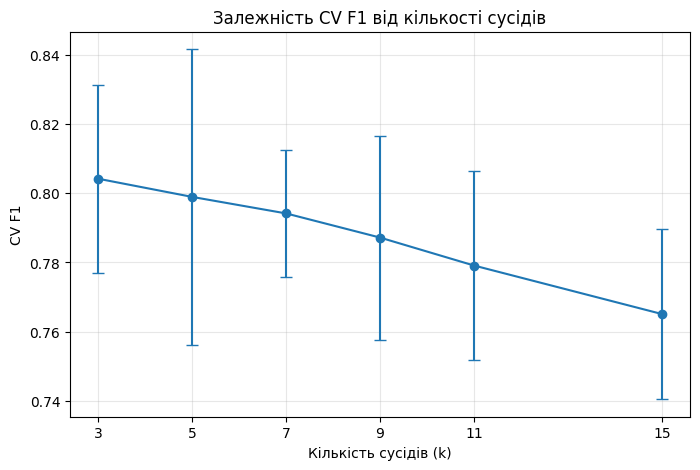

In [20]:

plt.figure(figsize=(8, 5))

plt.errorbar(
    knn_k_df["k"],
    knn_k_df["CV_F1"],
    yerr=knn_k_df["CV_F1_std"],
    marker="o",
    capsize=4
)

plt.title("Залежність CV F1 від кількості сусідів")
plt.xlabel("Кількість сусідів (k)")
plt.ylabel("CV F1")
plt.xticks(k_values)
plt.grid(alpha=0.3)
plt.show()


### Аналіз кількості сусідів

Мале значення k може призвести до перенавчання, а надто велике — до недонавчання. Оптимальне k визначається за результатами крос-валідації.

In [21]:

distance_results = []

for p, name in [(1, "Manhattan"), (2, "Euclidean")]:

    model = make_model_pipeline(
        KNeighborsClassifier(
            n_neighbors=best_k,
            p=p
        ),
        scale=True
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    distance_results.append({
        "Distance": name,
        "p": p,
        "CV_F1": scores["test_f1"].mean(),
        "CV_F1_std": scores["test_f1"].std(),
        "CV_ROC_AUC": scores["test_roc_auc"].mean()
    })

distance_df = pd.DataFrame(distance_results)
display(distance_df.round(3))


,Distance,p,CV_F1,CV_F1_std,CV_ROC_AUC
0,Manhattan,1,0.818,0.030,0.877
1,Euclidean,2,0.804,0.027,0.871


In [22]:

best_distance = distance_df.sort_values(
    ["CV_F1", "p"],
    ascending=[False, True]
).iloc[0]

best_p = int(best_distance["p"])

best_knn = make_model_pipeline(
    KNeighborsClassifier(
        n_neighbors=best_k,
        p=best_p
    ),
    scale=True
)

print("Найкраще k:", best_k)
print("Найкраща відстань:", best_distance["Distance"])
print("CV F1:", round(best_distance["CV_F1"], 3))


Найкраще k: 3
Найкраща відстань: Manhattan
CV F1: 0.818


## 2. Імовірнісні методи класифікації

Досліджуються Gaussian Naive Bayes, LDA та QDA. Моделі порівнюються за однаковою схемою крос-валідації на навчальних даних.

In [23]:

gnb_model = make_model_pipeline(
    GaussianNB(),
    scale=True
)

gnb_scores = cross_validate(
    gnb_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("GaussianNB:")
print("CV F1:", round(gnb_scores["test_f1"].mean(), 3))
print("CV ROC AUC:", round(gnb_scores["test_roc_auc"].mean(), 3))


GaussianNB:
CV F1: 0.749
CV ROC AUC: 0.877


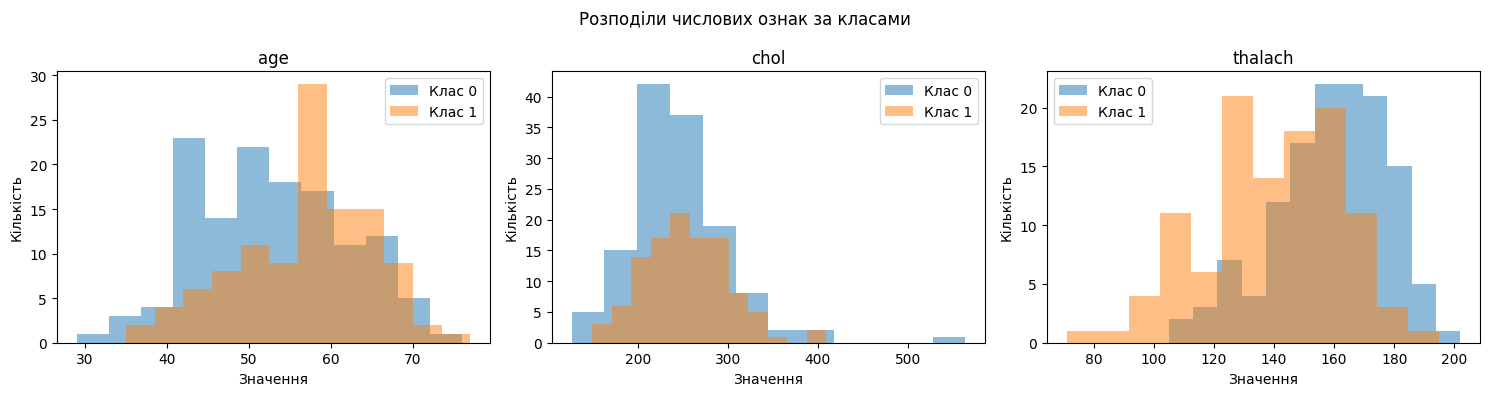

In [24]:

features_to_plot = ["age", "chol", "thalach"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, features_to_plot):

    for target_class in [0, 1]:
        values = X_train.loc[
            y_train == target_class, feature
        ].dropna()

        ax.hist(
            values,
            bins=12,
            alpha=0.5,
            label=f"Клас {target_class}"
        )

    ax.set_title(feature)
    ax.set_xlabel("Значення")
    ax.set_ylabel("Кількість")
    ax.legend()

plt.suptitle("Розподіли числових ознак за класами")
plt.tight_layout()
plt.show()


### Аналіз розподілів

Розподіли числових ознак можуть відрізнятися між класами та не завжди відповідають нормальному розподілу. Це може впливати на якість GaussianNB.

In [25]:

lda_model = make_model_pipeline(
    LinearDiscriminantAnalysis(),
    scale=True
)

lda_scores = cross_validate(
    lda_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

print("LDA:")
print("CV F1:", round(lda_scores["test_f1"].mean(), 3))
print("CV ROC AUC:", round(lda_scores["test_roc_auc"].mean(), 3))


LDA:
CV F1: 0.813
CV ROC AUC: 0.899


In [26]:

qda_results = []

for reg in [0, 0.01, 0.1]:

    model = make_model_pipeline(
        QuadraticDiscriminantAnalysis(
            reg_param=reg
        ),
        scale=True
    )

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")

        try:
            scores = cross_validate(
                model,
                X_train,
                y_train,
                cv=cv,
                scoring=scoring,
                error_score="raise"
            )

            result = {
                "reg_param": reg,
                "CV_F1": scores["test_f1"].mean(),
                "CV_F1_std": scores["test_f1"].std(),
                "CV_ROC_AUC": scores["test_roc_auc"].mean(),
                "Warnings": len(caught),
                "Error": ""
            }

        except (ValueError, np.linalg.LinAlgError) as e:
            result = {
                "reg_param": reg,
                "CV_F1": np.nan,
                "CV_F1_std": np.nan,
                "CV_ROC_AUC": np.nan,
                "Warnings": len(caught),
                "Error": str(e)[:120]
            }

    qda_results.append(result)

qda_df = pd.DataFrame(qda_results)
display(qda_df.round(3))


,reg_param,CV_F1,CV_F1_std,CV_ROC_AUC,Warnings,Error
0,0.00,0.571,0.143,0.761,10,
1,0.01,0.771,0.044,0.834,0,
2,0.10,0.796,0.027,0.868,0,


In [27]:

valid_qda = qda_df.dropna(subset=["CV_F1"]).copy()

if valid_qda.empty:
    best_qda = None
    print("QDA не вдалося коректно оцінити.")
else:
    valid_qda = valid_qda.sort_values(
        ["Warnings", "CV_F1"],
        ascending=[True, False]
    )

    best_qda_reg = float(valid_qda.iloc[0]["reg_param"])

    best_qda = make_model_pipeline(
        QuadraticDiscriminantAnalysis(
            reg_param=best_qda_reg
        ),
        scale=True
    )

    print("Обраний reg_param:", best_qda_reg)
    print("CV F1:", round(valid_qda.iloc[0]["CV_F1"], 3))
    print("Попереджень:", int(valid_qda.iloc[0]["Warnings"]))


Обраний reg_param: 0.1
CV F1: 0.796
Попереджень: 0


### Аналіз QDA

QDA може бути нестабільною через залежності між закодованими ознаками та особливості коваріаційних матриць. Регуляризація може покращити стійкість моделі.

In [28]:

def evaluate_cv(name, model):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring,
            error_score="raise"
        )

    return {
        "Model": name,
        "CV_F1": scores["test_f1"].mean(),
        "CV_F1_std": scores["test_f1"].std(),
        "CV_ROC_AUC": scores["test_roc_auc"].mean(),
        "Train_Time": scores["fit_time"].mean(),
        "Warnings": len(caught)
    }


In [29]:

models_pr5 = {
    "k-NN": best_knn,
    "GaussianNB": gnb_model,
    "LDA": lda_model
}

if best_qda is not None:
    models_pr5["QDA"] = best_qda

comparison_rows = []

for name, model in models_pr5.items():
    try:
        comparison_rows.append(evaluate_cv(name, model))
    except (ValueError, np.linalg.LinAlgError) as e:
        print(f"{name}: помилка оцінювання — {e}")

pr5_comparison = pd.DataFrame(comparison_rows)
pr5_comparison = pr5_comparison.sort_values(
    "CV_F1", ascending=False
)

display(pr5_comparison.round(3))


,Model,CV_F1,CV_F1_std,CV_ROC_AUC,Train_Time,Warnings
0,k-NN,0.818,0.030,0.877,0.032,0
2,LDA,0.813,0.026,0.899,0.031,0
3,QDA,0.796,0.027,0.868,0.025,0
1,GaussianNB,0.749,0.021,0.877,0.036,0


In [30]:

probability_results = pd.DataFrame({
    "Actual": y_train.iloc[:10].to_numpy()
})

probability_models = {
    "GaussianNB": gnb_model,
    "LDA": lda_model
}

if best_qda is not None:
    probability_models["QDA"] = best_qda

for name, model in probability_models.items():

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")

        try:
            probabilities = cross_val_predict(
                model,
                X_train,
                y_train,
                cv=cv,
                method="predict_proba"
            )

            # Класи в задачі: 0 та 1
            probability_results[f"{name}_OOF"] = probabilities[:10, 1]

            if caught:
                print(f"{name}: попереджень {len(caught)}")

        except (ValueError, np.linalg.LinAlgError) as e:
            print(f"{name}: не вдалося отримати ймовірності — {e}")

display(probability_results.round(3))


,Actual,GaussianNB_OOF,LDA_OOF,QDA_OOF
0,1,1.000,0.904,0.612
1,0,0.000,0.022,0.008
2,0,0.000,0.473,0.217
3,0,0.434,0.161,0.037
4,1,1.000,0.617,0.675
5,1,1.000,0.979,0.998
6,1,1.000,0.998,1.000
7,1,1.000,0.950,1.000
8,0,0.000,0.009,0.002
9,1,1.000,0.999,1.000


In [31]:

probabilistic_comparison = pr5_comparison[
    pr5_comparison["Model"].isin(
        ["GaussianNB", "LDA", "QDA"]
    )
].copy()

# Нестабільну QDA не обираємо фінальним кандидатом
probabilistic_comparison = probabilistic_comparison[
    (probabilistic_comparison["Model"] != "QDA")
    | (probabilistic_comparison["Warnings"] == 0)
]

best_prob_name = probabilistic_comparison.sort_values(
    "CV_F1", ascending=False
).iloc[0]["Model"]

best_prob_model = models_pr5[best_prob_name]

print("Найкраща k-NN:")
print("k =", best_k, ", p =", best_p)

print("\nНайкраща імовірнісна модель:")
print(best_prob_name)

display(pr5_comparison.round(3))


Найкраща k-NN:
k = 3 , p = 1

Найкраща імовірнісна модель:
LDA


,Model,CV_F1,CV_F1_std,CV_ROC_AUC,Train_Time,Warnings
0,k-NN,0.818,0.030,0.877,0.032,0
2,LDA,0.813,0.026,0.899,0.031,0
3,QDA,0.796,0.027,0.868,0.025,0
1,GaussianNB,0.749,0.021,0.877,0.036,0


## Висновки до практичної роботи №5

Під час роботи досліджено k-NN, GaussianNB, LDA та QDA.

Найкраще k — 3. Найкраща метрика відстані — Manhattan. Найкраща імовірнісна модель — LDA (CV F1 = 0.813).

Найвищу CV F1 серед досліджених моделей показала k-NN — 0.818. Тестову вибірку не використовували.

# Практична робота №6
## Метод опорних векторів і пошук гіперпараметрів

### Мета роботи

Побудувати лінійну та RBF-SVM, дослідити вплив параметрів C і gamma та визначити найкращу конфігурацію за крос-валідацією.

In [32]:

from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
import time


## 1. Лінійна SVM

Досліджується лінійна SVM зі стандартизацією числових ознак. Параметр C визначає силу штрафу за помилки класифікації.

In [33]:

linear_results = []

for c in [0.1, 1, 10]:

    model = make_model_pipeline(
        SVC(kernel="linear", C=c),
        scale=True
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    linear_results.append({
        "C": c,
        "CV_F1": scores["test_f1"].mean(),
        "CV_F1_std": scores["test_f1"].std(),
        "CV_ROC_AUC": scores["test_roc_auc"].mean(),
        "Train_Time": scores["fit_time"].mean()
    })

linear_df = pd.DataFrame(linear_results)

display(linear_df.round(3))


,C,CV_F1,CV_F1_std,CV_ROC_AUC,Train_Time
0,0.1,0.796,0.054,0.905,0.037
1,1.0,0.803,0.031,0.898,0.034
2,10.0,0.800,0.026,0.897,0.047


## 2. RBF-SVM

RBF-ядро дозволяє будувати нелінійну межу між класами. Параметр gamma визначає локальність впливу навчальних об’єктів, а C контролює штраф за помилки.

In [34]:

rbf_results = []

for c in [0.1, 1, 10]:
    for gamma in ["scale", 0.01, 0.1]:

        model = make_model_pipeline(
            SVC(
                kernel="rbf",
                C=c,
                gamma=gamma
            ),
            scale=True
        )

        scores = cross_validate(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring=scoring
        )

        rbf_results.append({
            "C": c,
            "gamma": gamma,
            "CV_F1": scores["test_f1"].mean(),
            "CV_F1_std": scores["test_f1"].std(),
            "CV_ROC_AUC": scores["test_roc_auc"].mean(),
            "Train_Time": scores["fit_time"].mean()
        })

rbf_df = pd.DataFrame(rbf_results)
display(rbf_df.round(3))


,C,gamma,CV_F1,CV_F1_std,CV_ROC_AUC,Train_Time
0,0.1,scale,0.763,0.016,0.886,0.048
1,0.1,0.01,0.246,0.113,0.882,0.041
2,0.1,0.1,0.765,0.017,0.885,0.044
3,1.0,scale,0.789,0.027,0.888,0.042
4,1.0,0.01,0.795,0.029,0.896,0.035
5,1.0,0.1,0.789,0.027,0.887,0.044
6,10.0,scale,0.748,0.023,0.823,0.035
7,10.0,0.01,0.827,0.033,0.897,0.032
8,10.0,0.1,0.756,0.033,0.823,0.041


## 3. Пошук гіперпараметрів

Для пошуку найкращої конфігурації використовується GridSearchCV з п'ятикратною стратифікованою крос-валідацією. Основною метрикою є F1.

In [35]:

svm_pipeline = make_model_pipeline(
    SVC(),
    scale=True
)

param_grid = [
    {
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1, 1, 10]
    },
    {
        "classifier__kernel": ["rbf"],
        "classifier__C": [0.1, 1, 10],
        "classifier__gamma": ["scale", 0.01, 0.1]
    }
]

svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring=scoring,
    refit="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=False
)

svm_grid.fit(X_train, y_train)

print("Найкращі параметри:")
print(svm_grid.best_params_)

print("\nНайкраща CV F1:")
print(round(svm_grid.best_score_, 3))


Найкращі параметри:
{'classifier__C': 10, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}

Найкраща CV F1:
0.827


In [36]:

svm_results = pd.DataFrame(svm_grid.cv_results_)

svm_comparison = svm_results[[
    "param_classifier__kernel",
    "param_classifier__C",
    "param_classifier__gamma",
    "mean_test_f1",
    "std_test_f1",
    "mean_test_roc_auc",
    "mean_fit_time"
]].copy()

svm_comparison.columns = [
    "Kernel",
    "C",
    "Gamma",
    "CV_F1",
    "CV_F1_std",
    "CV_ROC_AUC",
    "Train_Time"
]

svm_comparison = svm_comparison.sort_values(
    "CV_F1", ascending=False
)

display(svm_comparison.round(3))


,Kernel,C,Gamma,CV_F1,CV_F1_std,CV_ROC_AUC,Train_Time
10,rbf,10.0,0.01,0.827,0.033,0.897,0.216
1,linear,1.0,NaN,0.803,0.031,0.898,0.109
2,linear,10.0,NaN,0.800,0.026,0.897,0.157
0,linear,0.1,NaN,0.796,0.054,0.905,0.132
7,rbf,1.0,0.01,0.795,0.029,0.896,0.145
8,rbf,1.0,0.1,0.789,0.027,0.887,0.183
6,rbf,1.0,scale,0.789,0.027,0.888,0.080
5,rbf,0.1,0.1,0.765,0.017,0.885,0.105
3,rbf,0.1,scale,0.763,0.016,0.886,0.145
11,rbf,10.0,0.1,0.756,0.033,0.823,0.192


In [37]:

best_linear = linear_df.sort_values(
    "CV_F1", ascending=False
).iloc[0]

best_rbf = rbf_df.sort_values(
    "CV_F1", ascending=False
).iloc[0]

svm_final_comparison = pd.DataFrame([
    {
        "Model": "Linear SVM",
        "C": best_linear["C"],
        "gamma": "-",
        "CV_F1": best_linear["CV_F1"],
        "CV_F1_std": best_linear["CV_F1_std"],
        "CV_ROC_AUC": best_linear["CV_ROC_AUC"],
        "Train_Time": best_linear["Train_Time"]
    },
    {
        "Model": "RBF-SVM",
        "C": best_rbf["C"],
        "gamma": best_rbf["gamma"],
        "CV_F1": best_rbf["CV_F1"],
        "CV_F1_std": best_rbf["CV_F1_std"],
        "CV_ROC_AUC": best_rbf["CV_ROC_AUC"],
        "Train_Time": best_rbf["Train_Time"]
    }
])

display(svm_final_comparison.round(3))


,Model,C,gamma,CV_F1,CV_F1_std,CV_ROC_AUC,Train_Time
0,Linear SVM,1.0,-,0.803,0.031,0.898,0.034
1,RBF-SVM,10.0,0.01,0.827,0.033,0.897,0.032


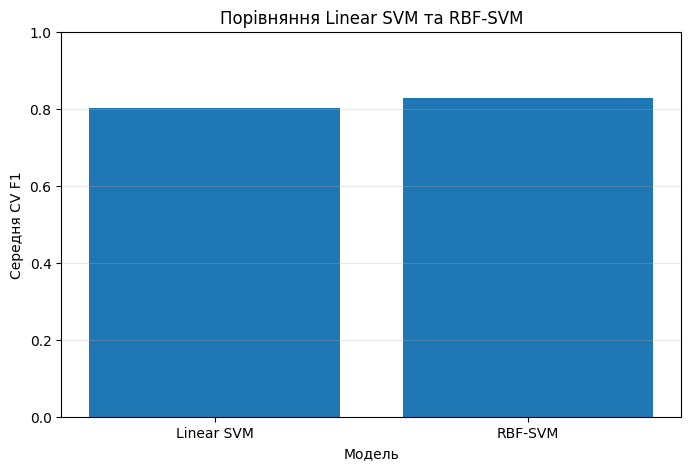

In [38]:

plt.figure(figsize=(8, 5))

plt.bar(
    svm_final_comparison["Model"],
    svm_final_comparison["CV_F1"]
)

plt.title("Порівняння Linear SVM та RBF-SVM")
plt.xlabel("Модель")
plt.ylabel("Середня CV F1")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)
plt.show()


In [39]:

best_svm = svm_grid.best_estimator_

best_svm_kernel = svm_grid.best_params_[
    "classifier__kernel"
]

best_svm_C = svm_grid.best_params_[
    "classifier__C"
]

print("Найкраще ядро:", best_svm_kernel)
print("Найкраще C:", best_svm_C)

if best_svm_kernel == "rbf":
    print(
        "Найкраще gamma:",
        svm_grid.best_params_["classifier__gamma"]
    )

print("CV F1:", round(svm_grid.best_score_, 3))


Найкраще ядро: rbf
Найкраще C: 10
Найкраще gamma: 0.01
CV F1: 0.827


## Висновки до практичної роботи №6

Під час роботи досліджено Linear SVM та RBF-SVM.

За допомогою GridSearchCV перевірено різні значення C і gamma. Моделі порівняно за CV F1, ROC AUC та часом навчання.

**Найкраще ядро:** rbf.

**Найкраще C:** 10.

**Найкраще gamma:** 0.01.

**Найкраща CV F1:** 0.827.

Найкращу конфігурацію обрано без використання тестової вибірки.

# Практична робота №7
## Порівняння моделей, фінальне тестування і збереження Pipeline

### Мета роботи

Порівняти класичні моделі класифікації, обрати найкращу за крос-валідацією, виконати одноразове тестування та зберегти фінальний Pipeline.

In [40]:

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from pathlib import Path
from sklearn.base import clone
from sklearn.model_selection import (
    cross_validate,
    cross_val_predict
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay
)


## 1. Підготовка моделей-кандидатів

Для фінального порівняння використовуються найкращі конфігурації алгоритмів, отримані в практичних роботах №4–6.

In [41]:

candidate_models = {
    "Logistic Regression": grid.best_estimator_,
    "k-NN": best_knn,
    "GaussianNB": gnb_model,
    "LDA": lda_model,
    "SVM": best_svm
}

# Додаємо QDA лише за відсутності попереджень
if best_qda is not None:
    qda_selected = valid_qda.iloc[0]

    if int(qda_selected["Warnings"]) == 0:
        candidate_models["QDA"] = best_qda
    else:
        print("QDA не включено через нестабільність.")

print("Моделі для порівняння:")
for name in candidate_models:
    print("-", name)


Моделі для порівняння:
- Logistic Regression
- k-NN
- GaussianNB
- LDA
- SVM
- QDA


In [42]:

cv_results = []

for name, model in candidate_models.items():

    scores = cross_validate(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        scoring={
            "f1": "f1",
            "roc_auc": "roc_auc",
            "recall": "recall"
        },
        error_score="raise"
    )

    params = model.named_steps["classifier"].get_params()

    if name == "Logistic Regression":
        settings = f"C={params['C']}, penalty={params['penalty']}"
    elif name == "k-NN":
        settings = f"k={params['n_neighbors']}, p={params['p']}"
    elif name == "SVM":
        settings = f"kernel={params['kernel']}, C={params['C']}"
        if params["kernel"] == "rbf":
            settings += f", gamma={params['gamma']}"
    elif name == "QDA":
        settings = f"reg_param={params['reg_param']}"
    else:
        settings = "default"

    cv_results.append({
        "Model": name,
        "Parameters": settings,
        "CV_F1": scores["test_f1"].mean(),
        "CV_F1_std": scores["test_f1"].std(),
        "CV_Recall": scores["test_recall"].mean(),
        "CV_ROC_AUC": scores["test_roc_auc"].mean(),
        "Train_Time": scores["fit_time"].mean()
    })

cv_comparison = pd.DataFrame(cv_results)

cv_comparison = cv_comparison.sort_values(
    ["CV_F1", "CV_Recall", "CV_F1_std"],
    ascending=[False, False, True]
).reset_index(drop=True)

display(cv_comparison.round(3))


,Model,Parameters,CV_F1,CV_F1_std,CV_Recall,CV_ROC_AUC,Train_Time
0,Logistic Regression,"C=10, penalty=l2",0.836,0.013,0.802,0.900,0.093
1,SVM,"kernel=rbf, C=10, gamma=0.01",0.827,0.033,0.783,0.897,0.056
2,k-NN,"k=3, p=1",0.818,0.030,0.792,0.877,0.050
3,LDA,default,0.813,0.026,0.766,0.899,0.057
4,QDA,reg_param=0.1,0.796,0.027,0.774,0.868,0.076
5,GaussianNB,default,0.749,0.021,0.846,0.877,0.083


In [43]:

REPORTS_DIR = MINI_DIR / "reports"
MODELS_DIR = MINI_DIR / "models"

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

CV_RESULTS_PATH = REPORTS_DIR / "cv_model_comparison.csv"
TEST_RESULTS_PATH = REPORTS_DIR / "final_test_metrics.csv"
MODEL_PATH = MODELS_DIR / "best_classifier.joblib"

cv_comparison.to_csv(
    CV_RESULTS_PATH,
    index=False
)

print("CV-результати збережено:", CV_RESULTS_PATH)


CV-результати збережено: /content/drive/MyDrive/patternrecognition-practice/classification-mini-project/reports/cv_model_comparison.csv


## 2. Крос-валідаційні ROC-криві

Для порівняння моделей будуються ROC-криві на основі позавибіркових прогнозів навчальної вибірки. Тестові дані не використовуються.

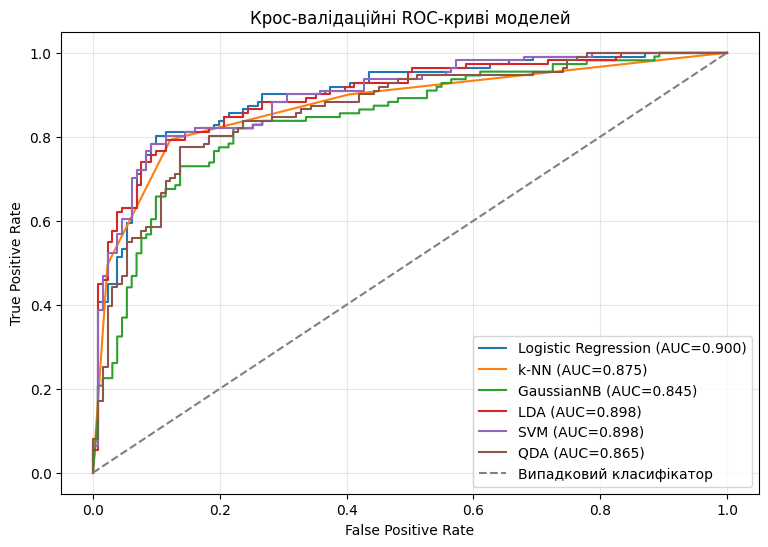

In [44]:

plt.figure(figsize=(9, 6))

oof_scores = {}
oof_predictions = {}

for name, model in candidate_models.items():

    # Прогнози класів
    predictions = cross_val_predict(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        method="predict"
    )

    oof_predictions[name] = predictions

    # Оцінки для ROC-кривої
    method = (
        "decision_function"
        if name == "SVM"
        else "predict_proba"
    )

    scores = cross_val_predict(
        clone(model),
        X_train,
        y_train,
        cv=cv,
        method=method
    )

    if method == "predict_proba":
        positive_scores = scores[:, 1]
    else:
        positive_scores = scores

    oof_scores[name] = positive_scores

    fpr, tpr, _ = roc_curve(
        y_train, positive_scores
    )

    auc_value = roc_auc_score(
        y_train, positive_scores
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC={auc_value:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Випадковий класифікатор"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Крос-валідаційні ROC-криві моделей")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Аналіз ROC-кривих

Чим ближче ROC-крива до лівого верхнього кута та чим вище ROC AUC, тим краще модель розділяє класи. Порівняння виконано без використання тестової вибірки.

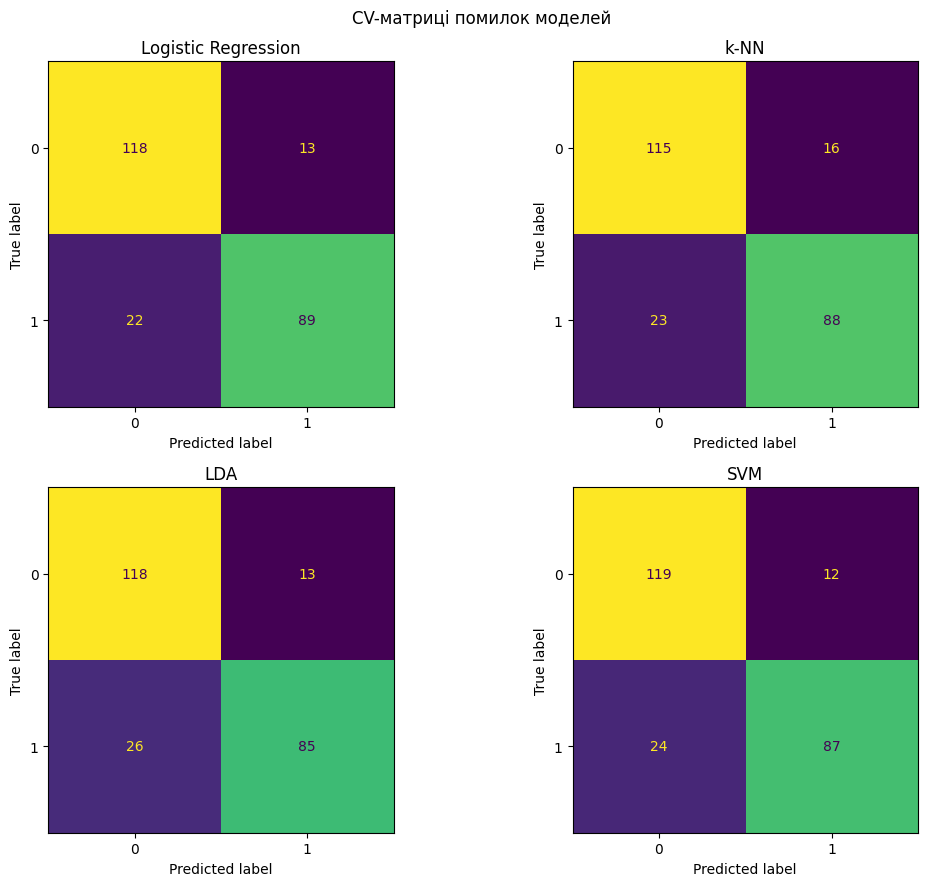

In [45]:

models_to_show = [
    "Logistic Regression",
    "k-NN",
    best_prob_name,
    "SVM"
]

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, name in zip(axes.flat, models_to_show):

    cm = confusion_matrix(
        y_train,
        oof_predictions[name],
        labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[0, 1]
    ).plot(
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.suptitle("CV-матриці помилок моделей")
plt.tight_layout()
plt.show()


### Аналіз матриць помилок

Матриці показують кількість правильних і помилкових прогнозів. Особливу увагу приділено False Negative — випадкам, коли модель не виявила позитивний клас.

In [46]:

winner = cv_comparison.iloc[0]

final_model_name = winner["Model"]
final_pipeline = clone(
    candidate_models[final_model_name]
)

print("Фінальна модель:", final_model_name)
print("CV F1:", round(winner["CV_F1"], 3))
print("CV ROC AUC:", round(winner["CV_ROC_AUC"], 3))
print("CV Recall:", round(winner["CV_Recall"], 3))
print("CV F1 std:", round(winner["CV_F1_std"], 3))
print("Параметри:", winner["Parameters"])


Фінальна модель: Logistic Regression
CV F1: 0.836
CV ROC AUC: 0.9
CV Recall: 0.802
CV F1 std: 0.013
Параметри: C=10, penalty=l2


## 3. Вибір фінальної моделі

Фінальною обрано модель **Logistic Regression**. Її середня CV F1 становить **0.836**, а CV ROC AUC — **0.900**. Стандартне відхилення CV F1 дорівнює **0.013**.

Модель показала найкращий результат за основною метрикою. Її перевагою є висока якість класифікації та стабільність результатів.

**Гіперпараметри:** C=10, penalty=L2.

**Фінальний вибір зроблено до оцінювання на test.**

## 4. Фінальне тестування

Після фіксації найкращої моделі її навчають на всій навчальній вибірці. Тестова вибірка використовується одноразово для незалежного оцінювання якості.

In [47]:

final_pipeline.fit(
    X_train,
    y_train
)

print("Фінальну модель навчено.")
print("Модель:", final_model_name)


Фінальну модель навчено.
Модель: Logistic Regression


In [48]:

test_predictions = final_pipeline.predict(
    X_test
)

# Оцінка позитивного класу для ROC AUC
if hasattr(final_pipeline, "predict_proba"):
    test_scores = final_pipeline.predict_proba(
        X_test
    )[:, 1]
    score_type = "probability"
else:
    test_scores = final_pipeline.decision_function(
        X_test
    )
    score_type = "decision_function"

test_metrics = pd.DataFrame([{
    "Model": final_model_name,
    "Accuracy": accuracy_score(
        y_test, test_predictions
    ),
    "Precision": precision_score(
        y_test, test_predictions,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test, test_predictions,
        zero_division=0
    ),
    "F1": f1_score(
        y_test, test_predictions,
        zero_division=0
    ),
    "ROC_AUC": roc_auc_score(
        y_test, test_scores
    )
}])

display(test_metrics.round(3))


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.869,0.833,0.893,0.862,0.962


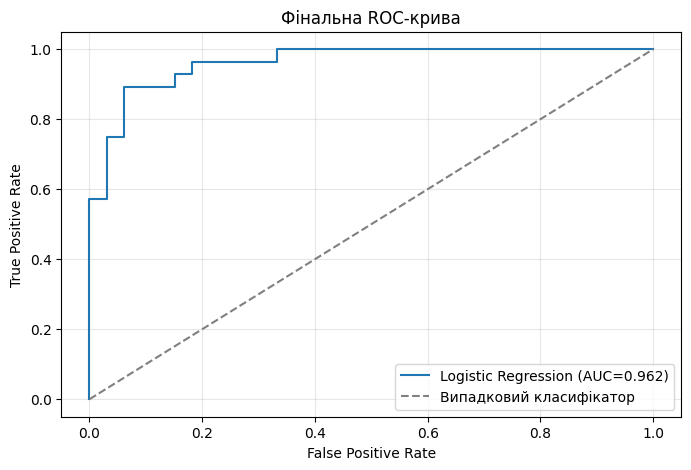

In [49]:

fpr, tpr, thresholds = roc_curve(
    y_test,
    test_scores
)

final_auc = roc_auc_score(
    y_test,
    test_scores
)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"{final_model_name} (AUC={final_auc:.3f})"
)

plt.plot(
    [0, 1], [0, 1],
    "--",
    color="gray",
    label="Випадковий класифікатор"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Фінальна ROC-крива")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


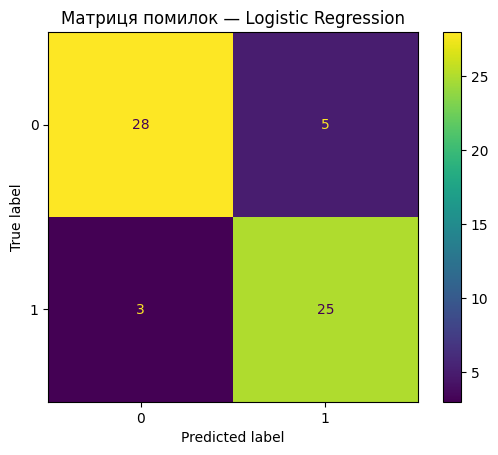

In [50]:

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=[0, 1]
)

plt.title(f"Матриця помилок — {final_model_name}")
plt.show()


### Аналіз фінальних результатів

Фінальна оцінка проведена на незалежній тестовій вибірці. ROC-крива показує здатність моделі розділяти класи, а матриця помилок — правильні та неправильні прогнози.

In [51]:

test_analysis = X_test.copy()

test_analysis["actual"] = y_test
test_analysis["predicted"] = test_predictions
test_analysis["positive_score"] = test_scores

test_analysis["correct"] = (
    test_analysis["actual"]
    == test_analysis["predicted"]
)

mistakes = test_analysis[
    ~test_analysis["correct"]
].copy()

mistakes.index.name = "original_index"

print("Кількість помилок:", len(mistakes))
print("Тип оцінки:", score_type)

display(mistakes)


Кількість помилок: 8
Тип оцінки: probability


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,actual,predicted,positive_score,correct
original_index,,,,,,,,,,,,,,,,,
271,66,1,4,160,228,0,2,138,0,2.3,1,0.0,6.0,0,1,0.516062,False
196,69,1,1,160,234,1,2,131,0,0.1,2,1.0,3.0,0,1,0.708839,False
33,59,1,4,135,234,0,0,161,0,0.5,2,0.0,7.0,0,1,0.781471,False
292,44,1,4,120,169,0,0,144,1,2.8,3,0.0,6.0,1,0,0.410501,False
287,58,1,2,125,220,0,0,144,0,0.4,2,NaN,7.0,0,1,0.597043,False
66,60,1,3,140,185,0,2,155,0,3.0,2,0.0,3.0,1,0,0.249274,False
92,62,1,3,130,231,0,0,146,0,1.8,2,3.0,7.0,0,1,0.925454,False
172,59,0,4,174,249,0,0,143,1,0.0,2,0.0,3.0,1,0,0.462026,False


### Аналіз помилкових прогнозів

Виявлено **8** помилкових прогнозів. Помилки можуть виникати через схожість характеристик об’єктів різних класів та обмежену здатність моделі їх розділяти. Результати проаналізовано без повторного налаштування моделі.

In [52]:

test_metrics.to_csv(
    TEST_RESULTS_PATH,
    index=False
)

print("Файл збережено:", TEST_RESULTS_PATH)


Файл збережено: /content/drive/MyDrive/patternrecognition-practice/classification-mini-project/reports/final_test_metrics.csv


## 5. Збереження фінальної моделі

Фінальний Pipeline зберігається разом з усіма етапами попередньої обробки, що дозволяє використовувати його без ручного масштабування чи кодування ознак.

In [53]:

joblib.dump(
    final_pipeline,
    MODEL_PATH
)

print("Модель збережено:", MODEL_PATH)
print("Файл існує:", MODEL_PATH.exists())


Модель збережено: /content/drive/MyDrive/patternrecognition-practice/classification-mini-project/models/best_classifier.joblib
Файл існує: True


In [54]:

loaded_pipeline = joblib.load(
    MODEL_PATH
)

check_objects = X_test.head(3)

loaded_predictions = loaded_pipeline.predict(
    check_objects
)

original_predictions = final_pipeline.predict(
    check_objects
)

print("Прогнози завантаженої моделі:")
print(loaded_predictions)

assert np.array_equal(
    loaded_predictions,
    original_predictions
)

print("Перевірка успішна.")


Прогнози завантаженої моделі:
[0 1 0]
Перевірка успішна.


# Загальні висновки

Під час практичних робіт №4–7 досліджено Logistic Regression, k-NN, GaussianNB, LDA, QDA та SVM.

Виконано підготовку даних за допомогою Pipeline, масштабування ознак і підбір гіперпараметрів за крос-валідацією.

Для k-NN найкращими виявилися k=3 та Manhattan. Серед імовірнісних моделей найкращою стала LDA (CV F1 = 0.813).

Фінальною моделлю обрано **Logistic Regression** з параметрами C=10 та L2-регуляризацією (CV F1 = 0.836).

На тестовій вибірці отримано:
- Accuracy — 0.869;
- Precision — 0.833;
- Recall — 0.893;
- F1 — 0.862;
- ROC AUC — 0.962.

Модель допустила **8 помилок із 61 прогнозу**. Результати підтвердили хорошу узагальнювальну здатність моделі.

Фінальний Pipeline збережено для подальшого використання.